In [39]:
import equinox as eqx
import zodiax as zdx
import optax
import jax
import jax.numpy as np
import dLux as dl
import dLux.utils as dlu
from mplc_model import MPLC
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

In [60]:
#Define MPLC parameters
diameter = 1e-3  # Aperture diameter
num_planes = 3  # Number of phase screens
total_length = 50.0e-3 # Initial total length of the system
center_wavel = 1.55e-6  # Center wavelength for the system
wavelengths = np.array([center_wavel])  # Wavelengths of the input modes

In [71]:
#Load input mode
input_mode = np.load('mplc_input_single_mode.npy')
wf_npixels = input_mode.shape[-1]

#normalize input mode
input_mode = input_mode / np.sqrt(np.sum(np.abs(input_mode)**2))

# plt.figure()
# plt.imshow(np.abs(input_mode), cmap='gray')

In [72]:
#Calculate output mode
focal_length = 25.5e-3  # Effective focal length for spot generation

# Generate output modes by propagating a circular aperture
wf_npix = input_mode.shape[0]  # Number of pixels in the wavefront
circ_aper = dlu.circular_aperture(npixels=wf_npix, diameter = diameter, oversample=5)
circ_aper = circ_aper / np.sqrt(np.sum(np.abs(circ_aper)**2))  # Normalize the circular aperture
circ_aperture = dl.TransmissiveLayer(circ_aper, normalise=True)

# Define the propagator for generating the output modes (Pupil -> Focal)
psf_npix = 64  # Number of pixels in the PSF
psf_pixel_scale = 2e-6*256/64 # Pixel scale in the PSF plane
to_focal = dl.MFTPropagator(
    [
        ("ThinLens", dl.ABCDConjugatePlane(focal_length)),  # Pupil -> Focal
    ],
    dl.CoordSpec(n=psf_npix, d=psf_pixel_scale),
)

# Define the optical layers for generating the output modes
layers_mode_gen = [
    ("aperture", circ_aperture),
    ("to_focal", to_focal),
]

# Construct the optics object for generating the output modes
optics_mode_gen = dl.LayeredOpticalSystem(
    wf_npixels=wf_npix,
    diameter=diameter,
    layers=layers_mode_gen,
)

psf = optics_mode_gen.propagate(center_wavel, return_wf=True)
output_mode = psf.phasor[0]

# plt.figure(figsize=(15, 4))
# plt.imshow(circ_aper)

# plt.figure(figsize=(15, 4))
# plt.imshow(np.abs(output_mode)**2)

In [73]:
mplc = MPLC(
    input_modes = np.array([input_mode]),
    target_modes = np.array([output_mode]),
    diameter = diameter,
    num_planes = num_planes,
    total_length = total_length,
    wavelengths = wavelengths
)

In [74]:
# #make 3 randomized initial phase screens
# key = jax.random.PRNGKey(0)
# initial_phase_screens = jax.random.uniform(key, (3, mplc.wf_npixels, mplc.wf_npixels)) * 2 * np.pi

#initialize the phase screens with zeros
initial_phase_screens = np.zeros((num_planes, mplc.wf_npixels, mplc.wf_npixels))

In [95]:
#Define wavefront matching loss function
@eqx.filter_jit
@eqx.filter_value_and_grad
def loss_fn_WFM(params, mplc):
    phase_screens = np.stack([params[f'phase_screen_{i}'] for i in range(num_planes)])

    total_length = params['total_length']

    #call the mplc with the clipped phase screens and the total length
    res = mplc(phase_screens, total_length)

    #calculate the loss (summed over wavelengths and modes)
    #expand the target modes to match the shape of res
    target_modes_expanded = np.expand_dims(mplc.target_modes, axis=1)

    #calculate the overlap integral between the output modes and the target modes
    overlap = np.sum(np.conj(res) * target_modes_expanded, axis=(-2, -1))

    #calculate the loss as 1 - the mean of the squared magnitude of the overlap
    loss = 1 - np.mean(np.abs(overlap)**2)
    return loss

In [119]:
params = {}
for i in range(num_planes):
    params[f'phase_screen_{i}'] = initial_phase_screens[i]
params['total_length'] = np.array(total_length)

optimizers = {}
for i in range(num_planes):
    optimizers[f'phase_screen_{i}'] = optax.adam(learning_rate=1e-2)
optimizers['total_length'] = optax.adam(learning_rate=1e-3)
optim, opt_state = zdx.map_optimisers(params, optimizers)

#test the loss function
initial_loss, initial_grad = loss_fn_WFM(params, mplc)
print("Initial loss:", initial_loss)
print("Initial gradient norm:", optax.global_norm(initial_grad))

Initial loss: 0.9858914
Initial gradient norm: 0.339407


In [120]:
# Run the optimisation loop
losses, params_out = [], []
num_iters = 3000
with tqdm(range(num_iters),desc='Gradient Descent') as t:
    for i in t: 
        loss, grads = loss_fn_WFM(params, mplc)
        updates, opt_state = optim.update(grads, opt_state)
        params = eqx.apply_updates(params, updates)
        params_out.append(params)
        losses.append(loss)
        t.set_description("Loss: {:.3f}".format(loss)) # update the progress bar
losses = np.array(losses)

Gradient Descent:   0%|          | 0/3000 [00:00<?, ?it/s]

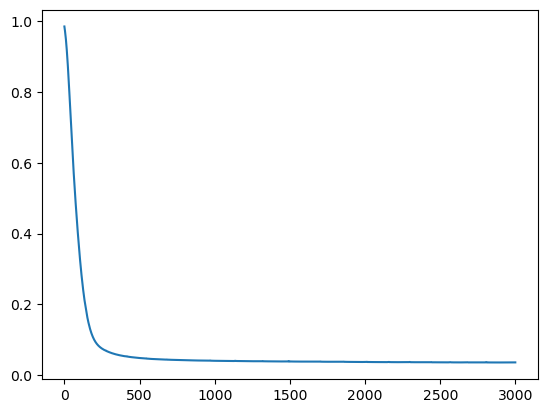

In [121]:
plt.figure()
plt.plot(losses)

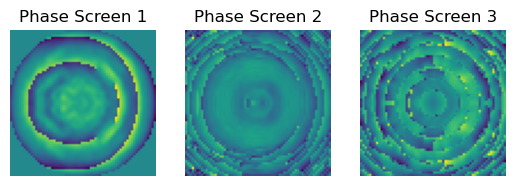

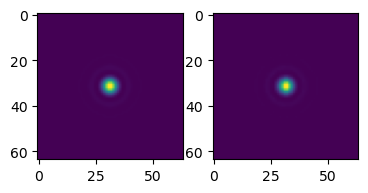

In [122]:
#plot the final phase screens
phase_screens_final = np.stack([params[f'phase_screen_{i}'] for i in range(num_planes)])

plt.figure()
for n in range(num_planes):
    plt.subplot(1, num_planes, n+1)
    plt.imshow(phase_screens_final[n])
    plt.title(f'Phase Screen {n+1}')
    plt.axis('off')

#propagate the input mode through the final phase screens and the final total length
res_final = mplc(phase_screens_final, params['total_length'])

#plot the target mode and the final output mode
plt.figure()
plt.subplot(1,3,1)
plt.imshow(np.abs(mplc.target_modes[0])**2)
plt.subplot(1,3,2)
plt.imshow(np.abs(res_final[0,0])**2)

In [126]:
#smooth out phase screens with regularization
def smoothness_loss(phase_screens):
    gx = (phase_screens[:, 1:, :] - phase_screens[:, :-1, :])
    gy = (phase_screens[:, :, 1:] - phase_screens[:, :, :-1])
    return np.mean(gx**2) + np.mean(gy**2)

@eqx.filter_jit
@eqx.filter_value_and_grad
def loss_with_smoothing(params, mplc, lambda_smooth):
    phase_screens = np.stack([
        params[f"phase_screen_{i}"]
        for i in range(num_planes)
    ])

    overlap_loss, _ = loss_fn_WFM(params, mplc)
    smooth_loss = smoothness_loss(phase_screens)

    return overlap_loss + lambda_smooth * smooth_loss

In [127]:
# Run the optimisation loop
losses_smoothing, params_out_smoothing = [], []
num_iters = 3000
with tqdm(range(num_iters),desc='Gradient Descent') as t:
    for i in t: 
        loss, grads = loss_with_smoothing(params, mplc, lambda_smooth=1e-3)
        updates, opt_state = optim.update(grads, opt_state)
        params = eqx.apply_updates(params, updates)
        params_out_smoothing.append(params)
        losses_smoothing.append(loss)
        t.set_description("Loss: {:.3f}".format(loss)) # update the progress bar
losses_smoothing = np.array(losses_smoothing)

Gradient Descent:   0%|          | 0/3000 [00:00<?, ?it/s]

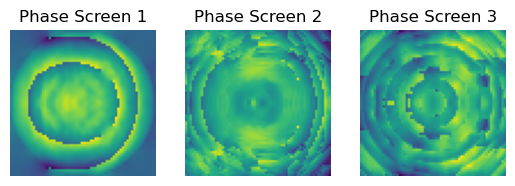

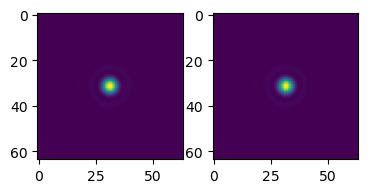

In [129]:
#plot the final phase screens
phase_screens_final = np.stack([params[f'phase_screen_{i}'] for i in range(num_planes)])

plt.figure()
for n in range(num_planes):
    plt.subplot(1, num_planes, n+1)
    plt.imshow(phase_screens_final[n])
    plt.title(f'Phase Screen {n+1}')
    plt.axis('off')

#propagate the input mode through the final phase screens and the final total length
res_final = mplc(phase_screens_final, params['total_length'])

#plot the target mode and the final output mode
plt.figure()
plt.subplot(1,3,1)
plt.imshow(np.abs(mplc.target_modes[0])**2)
plt.subplot(1,3,2)
plt.imshow(np.abs(res_final[0,0])**2)